In [1]:
# === Ô GHI LOG  ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "00_EDA_tong_hop_C2_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"   # log các notebook EDA để riêng
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 18:16:06 | INFO | Bắt đầu chạy 00_EDA_tong_hop_C2_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification/logs/2026-11-14_1816_00_EDA_tong_hop_C2_Han.log


# EDA tổng hợp E0.1 → E0.6 (C2 – Music Genre)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 14/11/2026 – sinh tự động bằng `notebooks/eda/gop_eda.py` từ 6 notebook con |
| **Câu hỏi nghiên cứu** | RQ0: Đặc trưng âm thanh nào phân biệt các thể loại tốt nhất? (E0.5 liên quan RQ1, E0.6 liên quan RQ4) |
| **Đọc vào** | `data/raw/train.csv`, `test.csv` |
| **Ghi ra** | `figures/eda/c2_E0.1_*` … `c2_E0.6_*` (giống 6 notebook con), `c2_E0_tong_hop_tom_tat.txt` |

Đây là **bản chính thức đọc từ trên xuống dưới** của toàn bộ phần EDA. Nội dung từng phần được chép
nguyên từ notebook con, chỉ bỏ các ô chuẩn bị bị lặp lại:

| Phần | Notebook con (nguồn gốc) |
|---|---|
| E0.1 | `01_E0.1_thong_ke_mo_ta_Han.ipynb` |
| E0.2 | `01_E0.2_xep_hang_dac_trung_Han.ipynb` |
| E0.3 | `01_E0.3_ngoai_lai_da_cong_tuyen_Han.ipynb` |
| E0.4 | `01_E0.4_so_dac_trung_toi_uu_Han.ipynb` |
| E0.5 | `01_E0.5_nghe_si_va_the_loai_Han.ipynb` |
| E0.6 | `01_E0.6_tach_lop_pca_tsne_Han.ipynb` |

**Sửa code:** sửa trong notebook con, rồi chạy `python notebooks/eda/gop_eda.py` để sinh lại file này.
**Cách chạy:** Run All. File log nằm ở `logs/eda_log/`. W&B tắt (các run E0.1–E0.6 đã log ngày 08/11).

---
# Phần E0.1
> Nguồn: `notebooks/eda/01_E0.1_thong_ke_mo_ta_Han.ipynb`

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Các run W&B của E0.1–E0.6 đã log ngày 08/11 (từ 01_eda_Han.ipynb).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-2-music-genre-classification"
log.info(f"ROOT: {ROOT}")

2026-11-14 18:16:08 | INFO | ROOT: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification


In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET, ID = "Class", "Id"
TEXT_COLS = ["Artist Name", "Track Name"]
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (14396, 18) | test: (3600, 17)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


## E0.1 – Dữ liệu trông thế nào?

Số mẫu, kiểu cột, tỉ lệ thiếu, số bài hát mỗi thể loại, và các điểm bất thường của dữ liệu.

In [4]:
X = train.drop(columns=[ID, TARGET])
y = train[TARGET]
num_cols = [c for c in X.columns if c not in TEXT_COLS]

overview = pd.DataFrame({
    "Chỉ số": ["Số mẫu train", "Số mẫu test", "Số thể loại", "Đặc trưng số", "Cột văn bản",
               "Số nghệ sĩ khác nhau (train)", "Số tên bài khác nhau (train)",
               "Tỉ lệ nghệ sĩ test đã có trong train", "Cột có giá trị thiếu (train)"],
    "Giá trị": [len(train), len(test), y.nunique(), len(num_cols), len(TEXT_COLS),
                train["Artist Name"].nunique(), train["Track Name"].nunique(),
                f"{test['Artist Name'].isin(train['Artist Name']).mean():.1%}",
                int((X.isna().sum() > 0).sum())],
})
overview.to_csv(FIG / "c2_E0.1_tong_quan.csv", index=False)
overview

,Chỉ số,Giá trị
0,Số mẫu train,14396
1,Số mẫu test,3600
2,Số thể loại,11
3,Đặc trưng số,14
4,Cột văn bản,2
5,Số nghệ sĩ khác nhau (train),7913
6,Số tên bài khác nhau (train),12455
7,Tỉ lệ nghệ sĩ test đã có trong train,63.8%
8,Cột có giá trị thiếu (train),3


In [5]:
# Bảng mô tả từng cột: kiểu, số giá trị khác nhau, tỉ lệ thiếu, nhỏ nhất, lớn nhất, ý nghĩa.
# Đề bài SHAI không kèm file mô tả cột; ý nghĩa các đặc trưng âm thanh ghi theo định nghĩa Audio Features của Spotify Web API.
y_nghia = {
    "Artist Name": "Tên nghệ sĩ",
    "Track Name": "Tên bài hát",
    "Popularity": "Độ phổ biến của bài hát (0–100)",
    "danceability": "Mức độ phù hợp để nhảy (0–1)",
    "energy": "Cường độ, độ sôi động (0–1)",
    "key": "Tông nhạc (0 = Đô, 1 = Đô thăng, …, 11 = Si)",
    "loudness": "Độ to trung bình của bài (dB)",
    "mode": "Điệu trưởng (1) hay điệu thứ (0)",
    "speechiness": "Mức độ có lời nói (0–1)",
    "acousticness": "Mức độ là nhạc mộc, không dùng điện (0–1)",
    "instrumentalness": "Khả năng bài không có lời hát (0–1)",
    "liveness": "Khả năng bài được thu trực tiếp có khán giả (0–1)",
    "valence": "Mức độ tích cực, vui vẻ (0–1)",
    "tempo": "Nhịp độ (số phách mỗi phút, BPM)",
    "duration_in min/ms": "Thời lượng bài hát (lẫn phút và mili giây, xem bên dưới)",
    "time_signature": "Số phách trong một ô nhịp",
}
bang_cot = pd.DataFrame({
    "kieu": ["văn bản" if c in TEXT_COLS else "số" for c in X.columns],
    "so_gia_tri_khac_nhau": [X[c].nunique() for c in X.columns],
    "ti_le_thieu": [X[c].isna().mean() for c in X.columns],
    "nho_nhat": [None if c in TEXT_COLS else X[c].min() for c in X.columns],
    "lon_nhat": [None if c in TEXT_COLS else X[c].max() for c in X.columns],
    "y_nghia": [y_nghia.get(c, "(chưa có mô tả)") for c in X.columns],
}, index=pd.Index(X.columns, name="cot"))
bang_cot.to_csv(FIG / "c2_E0.1_mo_ta_cot.csv")
log.info(f"Bảng mô tả cột: {len(bang_cot)} cột, {int((bang_cot['y_nghia'] == '(chưa có mô tả)').sum())} cột chưa có mô tả")
bang_cot.style.format({"ti_le_thieu": "{:.1%}"})

2026-11-14 18:16:08 | INFO | Bảng mô tả cột: 16 cột, 0 cột chưa có mô tả


,kieu,so_gia_tri_khac_nhau,ti_le_thieu,nho_nhat,lon_nhat,y_nghia
cot,,,,,,
Artist Name,văn bản,7913,0.0%,nan,nan,Tên nghệ sĩ
Track Name,văn bản,12455,0.0%,nan,nan,Tên bài hát
Popularity,số,100,2.3%,1.000000,100.000000,Độ phổ biến của bài hát (0–100)
danceability,số,887,0.0%,0.059600,0.989000,Mức độ phù hợp để nhảy (0–1)
energy,số,1156,0.0%,0.001210,1.000000,"Cường độ, độ sôi động (0–1)"
key,số,11,11.2%,1.000000,11.000000,"Tông nhạc (0 = Đô, 1 = Đô thăng, …, 11 = Si)"
loudness,số,8051,0.0%,-39.952000,1.342000,Độ to trung bình của bài (dB)
mode,số,2,0.0%,0.000000,1.000000,Điệu trưởng (1) hay điệu thứ (0)
speechiness,số,1177,0.0%,0.022500,0.955000,Mức độ có lời nói (0–1)


2026-11-14 18:16:08 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:16:08 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


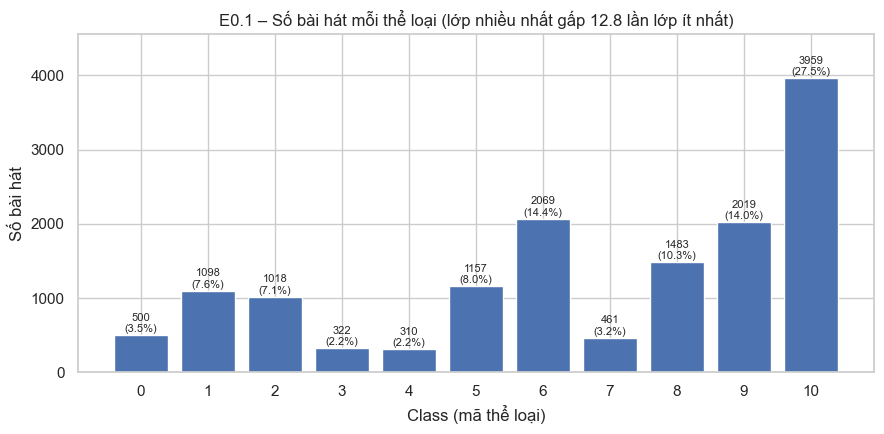

,so_bai,ti_le
Class,,
0,500,3.5%
1,1098,7.6%
2,1018,7.1%
3,322,2.2%
4,310,2.2%
5,1157,8.0%
6,2069,14.4%
7,461,3.2%
8,1483,10.3%


In [6]:
# Số bài hát mỗi thể loại
counts = y.value_counts().sort_index()
ratio = counts.max() / counts.min()
cls_tbl = counts.to_frame("so_bai").assign(ti_le=lambda d: d["so_bai"] / d["so_bai"].sum())
cls_tbl.to_csv(FIG / "c2_E0.1_phan_bo_lop.csv")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(counts.index.astype(str), counts.values, color="#4C72B0")
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v}\n({v / len(y):.1%})", ha="center", fontsize=8)
ax.set_xlabel("Class (mã thể loại)"); ax.set_ylabel("Số bài hát")
ax.set_title(f"E0.1 – Số bài hát mỗi thể loại (lớp nhiều nhất gấp {ratio:.1f} lần lớp ít nhất)")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); plt.savefig(FIG / "c2_E0.1_phan_bo_lop.png", dpi=150); plt.show()
cls_tbl.style.format({"ti_le": "{:.1%}"})

duration_in min/ms: 2075 bài ghi theo phút (giá trị < 30), 12321 bài ghi theo mili giây.
Giá trị key có trong dữ liệu: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] → không có key = 0 (nốt Đô) nhưng có 1609 ô trống.


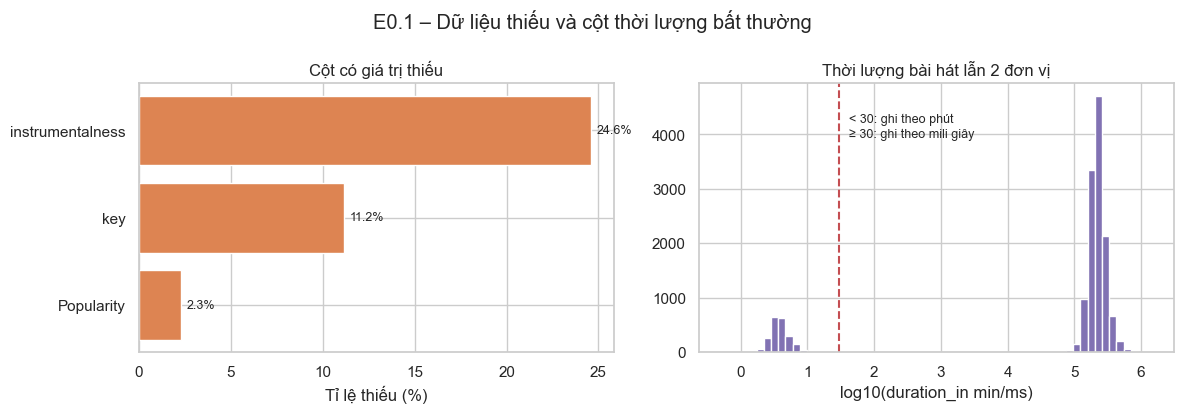

,so_thieu,ti_le
instrumentalness,3541,24.6%
key,1609,11.2%
Popularity,333,2.3%


In [7]:
# Tỉ lệ thiếu
miss = (pd.DataFrame({"so_thieu": X.isna().sum(), "ti_le": X.isna().mean()})
          .query("so_thieu > 0").sort_values("ti_le", ascending=False))
miss.to_csv(FIG / "c2_E0.1_ti_le_thieu.csv")

# Hai điểm bất thường
dur = train["duration_in min/ms"]
n_minutes = int((dur < 30).sum())
print(f"duration_in min/ms: {n_minutes} bài ghi theo phút (giá trị < 30), {int((dur >= 30).sum())} bài ghi theo mili giây.")
print("Giá trị key có trong dữ liệu:", sorted(int(v) for v in train["key"].dropna().unique()),
      f"→ không có key = 0 (nốt Đô) nhưng có {int(train['key'].isna().sum())} ô trống.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].barh(miss.index[::-1], miss["ti_le"][::-1] * 100, color="#DD8452")
for i, v in enumerate(miss["ti_le"][::-1] * 100):
    axes[0].text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_xlabel("Tỉ lệ thiếu (%)"); axes[0].set_title("Cột có giá trị thiếu")
axes[1].hist(np.log10(dur), bins=60, color="#8172B3")
axes[1].axvline(np.log10(30), color="#C44E52", ls="--")
axes[1].text(np.log10(30) * 1.1, axes[1].get_ylim()[1] * 0.8, "< 30: ghi theo phút\n≥ 30: ghi theo mili giây", fontsize=9)
axes[1].set_xlabel("log10(duration_in min/ms)"); axes[1].set_title("Thời lượng bài hát lẫn 2 đơn vị")
fig.suptitle("E0.1 – Dữ liệu thiếu và cột thời lượng bất thường")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.1_thieu_va_thoi_luong.png", dpi=150); plt.show()
miss.style.format({"ti_le": "{:.1%}"})

In [8]:
# Chuẩn hóa dữ liệu cho phân tích (không phải pipeline mô hình):
# - thời lượng đổi hết về phút
# - điền thiếu bằng trung vị
Xa = X[num_cols].copy()
Xa["duration_in min/ms"] = np.where(Xa["duration_in min/ms"] < 30, Xa["duration_in min/ms"],
                                    Xa["duration_in min/ms"] / 60000)
Xa = Xa.rename(columns={"duration_in min/ms": "duration_min"})
num_cols = list(Xa.columns)
Xa = Xa.fillna(Xa.median())

# Nghệ sĩ có phải gợi ý mạnh cho thể loại không?
# Với nghệ sĩ có từ 2 bài trở lên: tỉ lệ bài có cùng thể loại với thể loại phổ biến nhất của các bài còn lại
g = train.groupby("Artist Name")[TARGET]
multi = train[g.transform("size") >= 2]
def loo_match(df):
    out = []
    for i, cls in df[TARGET].items():
        rest = df[TARGET].drop(i)
        out.append(rest.mode().iloc[0] == cls)
    return pd.Series(out, index=df.index)
artist_match = multi.groupby("Artist Name", group_keys=False).apply(loo_match).mean()
print(f"{len(multi)} bài ({len(multi) / len(train):.1%}) thuộc nghệ sĩ có ≥ 2 bài; "
      f"{artist_match:.1%} trong số đó cùng thể loại với các bài khác của nghệ sĩ.")

9107 bài (63.3%) thuộc nghệ sĩ có ≥ 2 bài; 62.6% trong số đó cùng thể loại với các bài khác của nghệ sĩ.


## Tóm tắt E0.1

In [9]:
summary = f"""E0.1 (C2): {len(train)} bài train, {len(test)} bài test, {y.nunique()} thể loại, {len(num_cols)} đặc trưng số + 2 cột văn bản (Artist Name, Track Name).
  Mất cân bằng lớp: lớp {counts.idxmax()} có {counts.max()} bài, lớp {counts.idxmin()} có {counts.min()} bài (gấp {ratio:.1f} lần).
  Thiếu: {', '.join(f'{c} ({p:.0%})' for c, p in miss['ti_le'].items())}.
  duration_in min/ms lẫn 2 đơn vị ({n_minutes} bài ghi theo phút); key không có giá trị 0 nên ô trống nhiều khả năng là key = 0.
  {artist_match:.0%} bài của nghệ sĩ có ≥ 2 bài cùng thể loại với các bài khác của nghệ sĩ đó; {test['Artist Name'].isin(train['Artist Name']).mean():.0%} nghệ sĩ ở test đã có trong train."""
log.info("Tóm tắt E0.1:\n" + summary)
(FIG / "c2_E0.1_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:16:09 | INFO | Tóm tắt E0.1:
E0.1 (C2): 14396 bài train, 3600 bài test, 11 thể loại, 14 đặc trưng số + 2 cột văn bản (Artist Name, Track Name).
  Mất cân bằng lớp: lớp 10 có 3959 bài, lớp 4 có 310 bài (gấp 12.8 lần).
  Thiếu: instrumentalness (25%), key (11%), Popularity (2%).
  duration_in min/ms lẫn 2 đơn vị (2075 bài ghi theo phút); key không có giá trị 0 nên ô trống nhiều khả năng là key = 0.
  63% bài của nghệ sĩ có ≥ 2 bài cùng thể loại với các bài khác của nghệ sĩ đó; 64% nghệ sĩ ở test đã có trong train.


488

---
# Phần E0.2
> Nguồn: `notebooks/eda/01_E0.2_xep_hang_dac_trung_Han.ipynb`

## E0.2 – Yếu tố nào quan trọng nhất?

Bốn thước đo cho mỗi đặc trưng số (cột văn bản Artist/Track để riêng cho Nhung xử lý ở E2.2):

1. **Mutual information** với thể loại.
2. **ANOVA F**: trung bình đặc trưng có khác nhau giữa các thể loại không.
3. **Kruskal–Wallis H**: như ANOVA nhưng không giả định phân phối chuẩn.
4. **Macro-F1 đơn biến**: macro-F1 stratified 5-fold của hồi quy logistic chỉ dùng một đặc trưng.

Xếp hạng cuối là thứ hạng trung bình của bốn thước đo.

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))

disc = np.array([c in ["key", "mode", "time_signature"] for c in num_cols])
mi = pd.Series(mutual_info_classif(Xa, y, discrete_features=disc, random_state=SEED), index=num_cols)
f_stat = pd.Series(f_classif(Xa, y)[0], index=num_cols)
kw = pd.Series({c: stats.kruskal(*[Xa.loc[y == k, c] for k in sorted(y.unique())])[0] for c in num_cols})
f1_single = pd.Series({c: cross_val_score(logit(), Xa[[c]], y, cv=skf, scoring="f1_macro", n_jobs=-1).mean()
                       for c in num_cols})

scores = pd.DataFrame({"mutual_info": mi, "ANOVA_F": f_stat, "kruskal_H": kw, "macroF1_don_bien": f1_single})
scores["hang_trung_binh"] = scores.rank(ascending=False).mean(axis=1)
scores = scores.sort_values(["hang_trung_binh", "macroF1_don_bien"], ascending=[True, False])
scores.to_csv(FIG / "c2_E0.2_xep_hang_dac_trung.csv")
baseline_f1 = 1 / y.nunique()
print(f"Macro-F1 nếu đoán ngẫu nhiên đều các lớp ≈ {baseline_f1:.3f}")
scores.round(3)

Macro-F1 nếu đoán ngẫu nhiên đều các lớp ≈ 0.091


,mutual_info,ANOVA_F,kruskal_H,macroF1_don_bien,hang_trung_binh
acousticness,0.282,759.494,5259.593,0.143,1.25
energy,0.218,658.929,4049.752,0.153,2.00
danceability,0.153,457.338,3343.680,0.120,4.00
speechiness,0.152,690.551,2739.611,0.119,4.00
loudness,0.131,615.613,2487.975,0.132,4.50
instrumentalness,0.164,456.800,1870.686,0.060,6.25
Popularity,0.092,162.099,1361.928,0.075,7.25
valence,0.091,226.241,1949.440,0.072,7.25
duration_min,0.057,93.871,1080.501,0.073,8.75
tempo,0.074,31.780,306.108,0.048,10.75


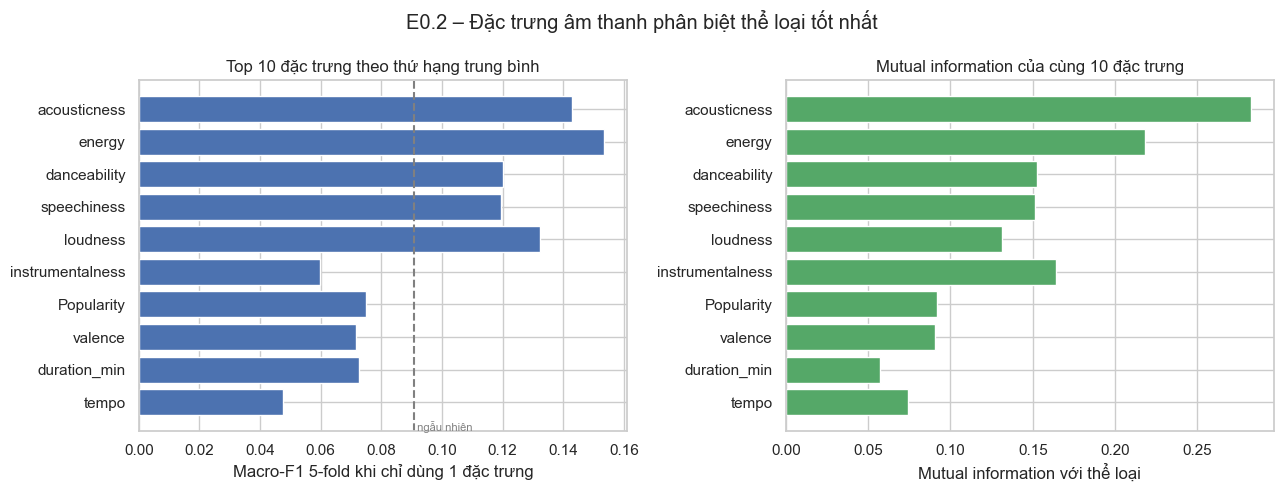

In [11]:
top10 = scores.head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(top10.index[::-1], top10["macroF1_don_bien"][::-1], color="#4C72B0")
axes[0].axvline(baseline_f1, ls="--", color="gray"); axes[0].text(baseline_f1, -0.9, " ngẫu nhiên", fontsize=8, color="gray")
axes[0].set_xlabel("Macro-F1 5-fold khi chỉ dùng 1 đặc trưng")
axes[0].set_title("Top 10 đặc trưng theo thứ hạng trung bình")
axes[1].barh(top10.index[::-1], top10["mutual_info"][::-1], color="#55A868")
axes[1].set_xlabel("Mutual information với thể loại")
axes[1].set_title("Mutual information của cùng 10 đặc trưng")
fig.suptitle("E0.2 – Đặc trưng âm thanh phân biệt thể loại tốt nhất")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.2_top10_dac_trung.png", dpi=150); plt.show()

2026-11-14 18:16:14 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:16:14 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:16:14 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:16:14 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:16:14 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:16:14 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:16:14 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:16:14 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


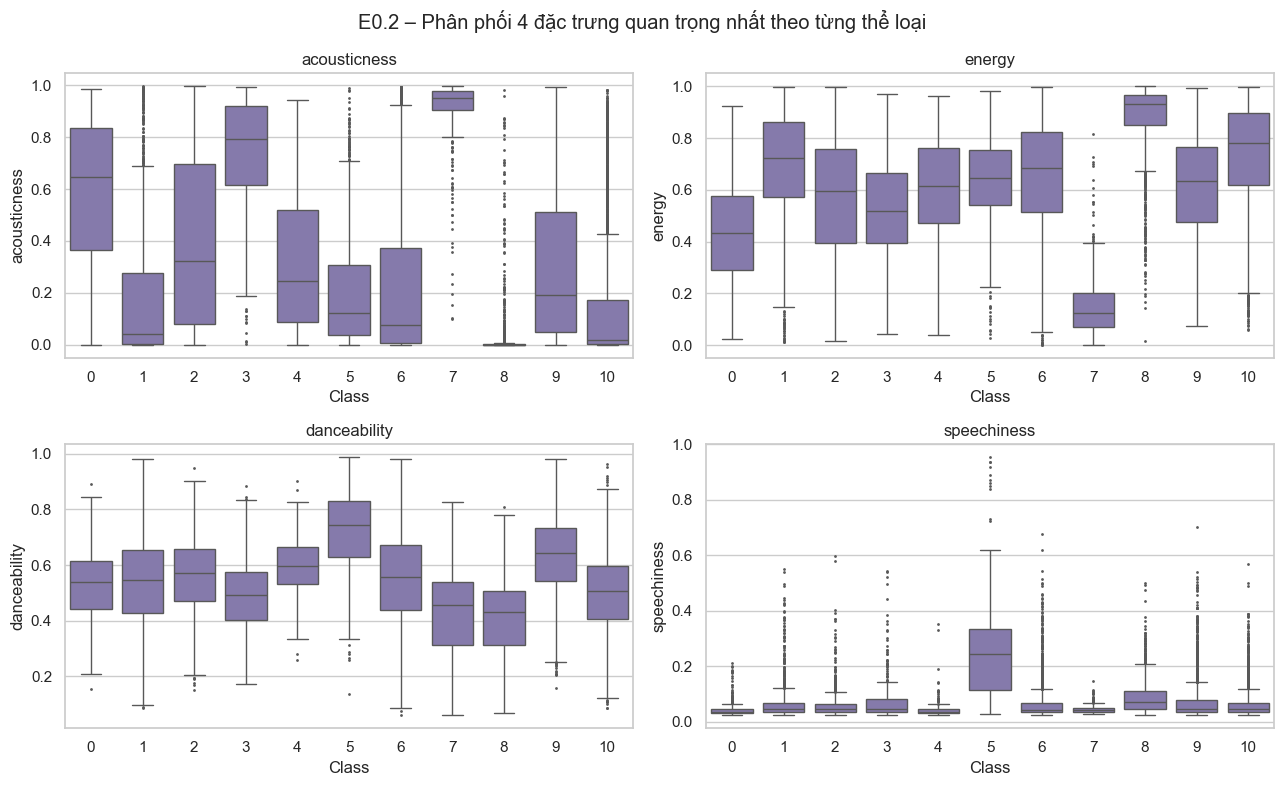

In [12]:
top4 = list(scores.index[:4])
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), top4):
    sns.boxplot(x=y, y=Xa[c], ax=ax, color="#8172B3", fliersize=1)
    ax.set_xlabel("Class"); ax.set_title(c)
fig.suptitle("E0.2 – Phân phối 4 đặc trưng quan trọng nhất theo từng thể loại")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.2_top4_theo_lop.png", dpi=150); plt.show()

## Tóm tắt E0.2

In [13]:
summary = f"""E0.2 (C2): xếp hạng đặc trưng: {', '.join(scores.index[:10])}.
  Đặc trưng đơn lẻ tốt nhất: {scores['macroF1_don_bien'].idxmax()} (macro-F1 = {scores['macroF1_don_bien'].max():.3f}, ngẫu nhiên ≈ {baseline_f1:.3f})."""
log.info("Tóm tắt E0.2:\n" + summary)
(FIG / "c2_E0.2_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:16:15 | INFO | Tóm tắt E0.2:
E0.2 (C2): xếp hạng đặc trưng: acousticness, energy, danceability, speechiness, loudness, instrumentalness, Popularity, valence, duration_min, tempo.
  Đặc trưng đơn lẻ tốt nhất: energy (macro-F1 = 0.153, ngẫu nhiên ≈ 0.091).


225

---
# Phần E0.3
> Nguồn: `notebooks/eda/01_E0.3_ngoai_lai_da_cong_tuyen_Han.ipynb`

## E0.3 – Có ngoại lai, đa cộng tuyến không?

- **Ngoại lai:** số điểm nằm ngoài [Q1 − 3·IQR, Q3 + 3·IQR] ở từng đặc trưng (sau khi đã đổi thời lượng về phút).
- **Đa cộng tuyến:** ma trận tương quan, các cặp |r| > 0.7, và hệ số VIF (VIF > 10 là đa cộng tuyến mạnh).

In [14]:
q1, q3 = Xa.quantile(0.25), Xa.quantile(0.75)
iqr = q3 - q1
extreme = ((Xa < q1 - 3 * iqr) | (Xa > q3 + 3 * iqr)) & (iqr > 0)
iqr_tbl = extreme.sum().sort_values(ascending=False).to_frame("so_diem_ngoai_lai")
iqr_tbl["ti_le"] = iqr_tbl["so_diem_ngoai_lai"] / len(Xa)
iqr_tbl = iqr_tbl.query("so_diem_ngoai_lai > 0")
iqr_tbl.to_csv(FIG / "c2_E0.3_ngoai_lai_IQR.csv")
print("Đặc trưng có ngoại lai cực đoan:")
iqr_tbl.style.format({"ti_le": "{:.1%}"})

Đặc trưng có ngoại lai cực đoan:


,so_diem_ngoai_lai,ti_le
instrumentalness,2607,18.1%
speechiness,1016,7.1%
liveness,259,1.8%
duration_min,206,1.4%
loudness,146,1.0%


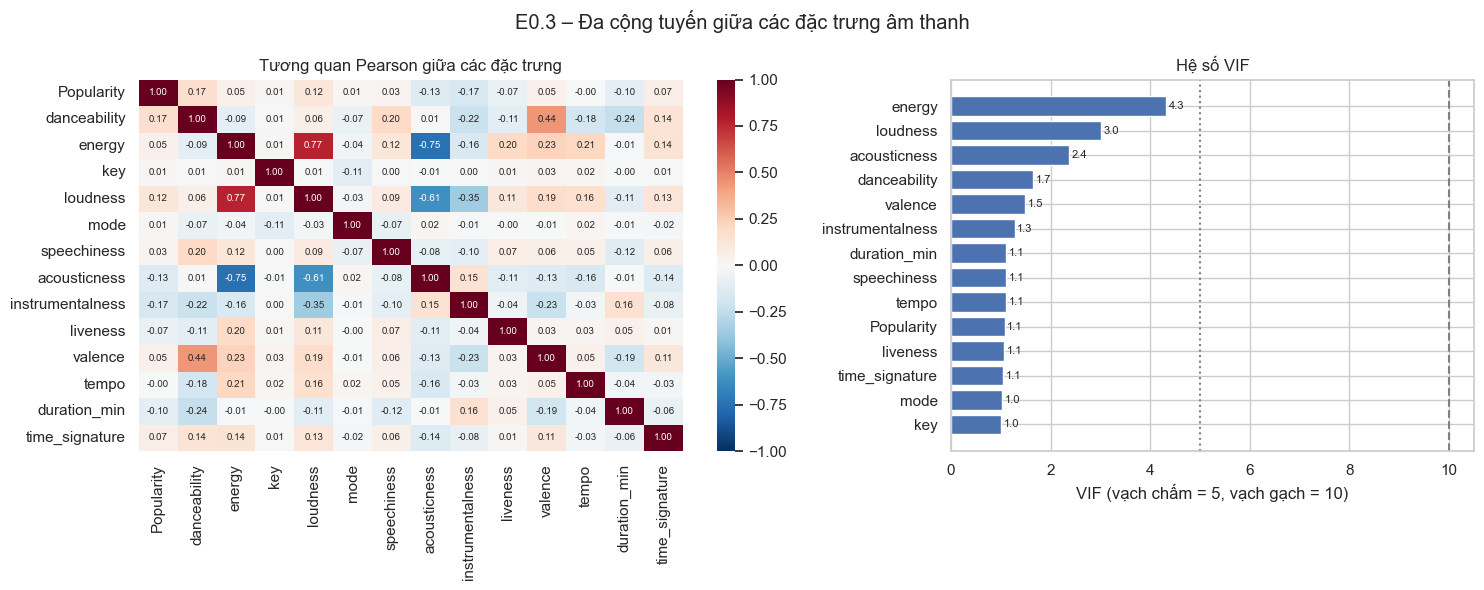

Cặp |tương quan| > 0.7:
dac_trung_1  dac_trung_2  tuong_quan
     energy     loudness        0.77
     energy acousticness       -0.75
VIF lớn nhất: energy 4.32


In [15]:
corr = Xa.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("tuong_quan").reset_index().rename(columns={"level_0": "dac_trung_1", "level_1": "dac_trung_2"}))
high_corr = pairs[pairs["tuong_quan"].abs() > 0.7].sort_values("tuong_quan", key=abs, ascending=False)
high_corr.to_csv(FIG / "c2_E0.3_cap_tuong_quan_cao.csv", index=False)

def vif_table(df):
    out = {}
    for c in df.columns:
        others = df.drop(columns=c)
        r2 = LinearRegression().fit(others, df[c]).score(others, df[c])
        out[c] = np.inf if r2 > 0.9999 else 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)
vif = vif_table(Xa).to_frame("VIF")
vif.to_csv(FIG / "c2_E0.3_vif.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0], annot_kws={"size": 7})
axes[0].set_title("Tương quan Pearson giữa các đặc trưng")
colors = ["#C44E52" if v > 10 else ("#DD8452" if v > 5 else "#4C72B0") for v in vif["VIF"]]
axes[1].barh(vif.index[::-1], vif["VIF"][::-1], color=colors[::-1])
for i, v in enumerate(vif["VIF"][::-1]):
    axes[1].text(v + 0.05, i, f"{v:.1f}", va="center", fontsize=8)
axes[1].axvline(5, ls=":", color="gray"); axes[1].axvline(10, ls="--", color="gray")
axes[1].set_xlabel("VIF (vạch chấm = 5, vạch gạch = 10)"); axes[1].set_title("Hệ số VIF")
fig.suptitle("E0.3 – Đa cộng tuyến giữa các đặc trưng âm thanh")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.3_tuong_quan_vif.png", dpi=150); plt.show()
print("Cặp |tương quan| > 0.7:"); print(high_corr.round(2).to_string(index=False))
print("VIF lớn nhất:", vif["VIF"].idxmax(), round(float(vif["VIF"].max()), 2))

## Tóm tắt E0.3

In [16]:
summary = f"""E0.3 (C2): ngoại lai cực đoan nhiều nhất ở {', '.join(f'{c} ({p:.1%})' for c, p in iqr_tbl['ti_le'].head(3).items())}.
  Cặp tương quan > 0.7: {'; '.join(f'{a}–{b} ({r:.2f})' for a, b, r in high_corr.itertuples(index=False)) or 'không có'}. VIF lớn nhất {vif['VIF'].idxmax()} = {vif['VIF'].max():.1f}."""
log.info("Tóm tắt E0.3:\n" + summary)
(FIG / "c2_E0.3_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:16:15 | INFO | Tóm tắt E0.3:
E0.3 (C2): ngoại lai cực đoan nhiều nhất ở instrumentalness (18.1%), speechiness (7.1%), liveness (1.8%).
  Cặp tương quan > 0.7: energy–loudness (0.77); energy–acousticness (-0.75). VIF lớn nhất energy = 4.3.


209

---
# Phần E0.4
> Nguồn: `notebooks/eda/01_E0.4_so_dac_trung_toi_uu_Han.ipynb`

## E0.4 – Bao nhiêu đặc trưng là đủ?

Chọn đặc trưng tuần tự tiến (forward SFS) với hồi quy logistic (chuẩn hóa, `class_weight="balanced"`), mỗi bước thêm đặc trưng làm macro-F1 stratified 5-fold tăng nhiều nhất. So sánh với đường lấy top-k theo xếp hạng E0.2. **Sweet spot** là số đặc trưng nhỏ nhất đạt macro-F1 cách mức cao nhất không quá 0.005.

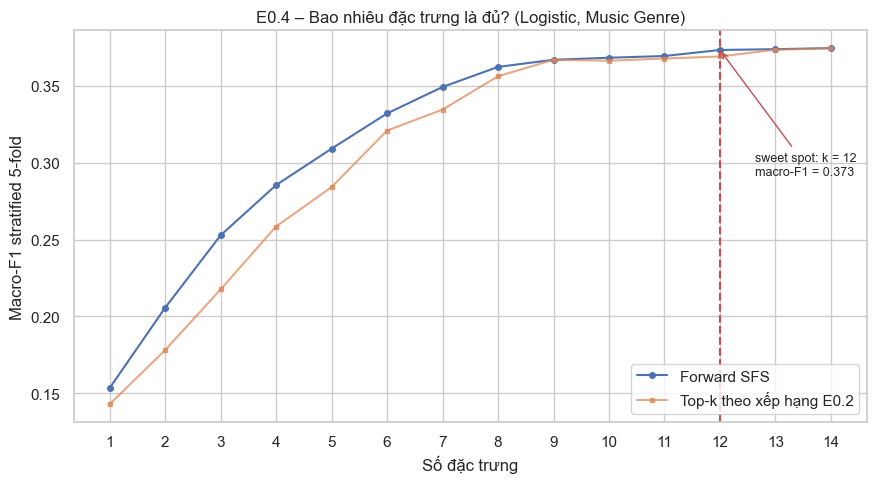

Sweet spot: 12 đặc trưng, macro-F1 = 0.373 (cao nhất 0.374)
Thứ tự SFS chọn: energy, speechiness, instrumentalness, acousticness, Popularity, valence, danceability, duration_min, loudness, time_signature, mode, liveness, key, tempo


In [17]:
def cv_f1(feats):
    return cross_val_score(logit(), Xa[feats], y, cv=skf, scoring="f1_macro", n_jobs=-1).mean()

selected, sfs_curve, remaining = [], [], list(num_cols)
while remaining:
    best = max(remaining, key=lambda f: cv_f1(selected + [f]))
    selected.append(best); remaining.remove(best)
    sfs_curve.append(cv_f1(selected))
rank_order = list(scores.index)
rank_curve = [cv_f1(rank_order[:k]) for k in range(1, len(num_cols) + 1)]

curve = pd.DataFrame({"k": range(1, len(num_cols) + 1), "dac_trung_them_vao": selected,
                      "macroF1_SFS": sfs_curve, "macroF1_top_k_E0.2": rank_curve})
best_f1 = curve["macroF1_SFS"].max()
sweet_k = int(curve.loc[curve["macroF1_SFS"] >= best_f1 - 0.005, "k"].min())
curve.to_csv(FIG / "c2_E0.4_duong_cong_so_dac_trung.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curve["k"], curve["macroF1_SFS"], marker="o", ms=4, label="Forward SFS")
ax.plot(curve["k"], curve["macroF1_top_k_E0.2"], marker="s", ms=3, alpha=0.7, label="Top-k theo xếp hạng E0.2")
ax.axvline(sweet_k, ls="--", color="#C44E52")
ax.annotate(f"sweet spot: k = {sweet_k}\nmacro-F1 = {curve.at[sweet_k-1, 'macroF1_SFS']:.3f}",
            (sweet_k, curve.at[sweet_k-1, "macroF1_SFS"]), textcoords="offset points", xytext=(25, -90),
            fontsize=9, arrowprops=dict(arrowstyle="->", color="#C44E52"))
ax.set_xticks(curve["k"])
ax.set_xlabel("Số đặc trưng"); ax.set_ylabel("Macro-F1 stratified 5-fold")
ax.set_title("E0.4 – Bao nhiêu đặc trưng là đủ? (Logistic, Music Genre)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig(FIG / "c2_E0.4_sweet_spot.png", dpi=150); plt.show()
print(f"Sweet spot: {sweet_k} đặc trưng, macro-F1 = {curve.at[sweet_k-1, 'macroF1_SFS']:.3f} (cao nhất {best_f1:.3f})")
print("Thứ tự SFS chọn:", ", ".join(selected))

## Tóm tắt E0.4

In [18]:
summary = f"""E0.4 (C2): sweet spot {sweet_k} đặc trưng, macro-F1 = {curve.at[sweet_k-1, 'macroF1_SFS']:.3f} (dùng hết {len(num_cols)}: {curve['macroF1_SFS'].iloc[-1]:.3f}).
  SFS chọn: {', '.join(selected[:sweet_k])}."""
log.info("Tóm tắt E0.4:\n" + summary)
(FIG / "c2_E0.4_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:16:28 | INFO | Tóm tắt E0.4:
E0.4 (C2): sweet spot 12 đặc trưng, macro-F1 = 0.373 (dùng hết 14: 0.374).
  SFS chọn: energy, speechiness, instrumentalness, acousticness, Popularity, valence, danceability, duration_min, loudness, time_signature, mode, liveness.


230

---
# Phần E0.5
> Nguồn: `notebooks/eda/01_E0.5_nghe_si_va_the_loai_Han.ipynb`

## E0.5 – Nghệ sĩ nói lên bao nhiêu về thể loại?

Ở E0.1 thấy phần lớn bài của cùng một nghệ sĩ có cùng thể loại. Thí nghiệm này đo xem thông tin đó mạnh tới mức nào, so ba cách dự đoán (stratified 5-fold, cùng các fold như E0.4):

1. **Chỉ âm thanh:** hồi quy logistic trên 14 đặc trưng số.
2. **Chỉ nghệ sĩ:** đoán thể loại phổ biến nhất của nghệ sĩ trong tập huấn luyện; nghệ sĩ chưa gặp thì đoán lớp đông nhất.
3. **Âm thanh + nghệ sĩ:** nghệ sĩ đã gặp thì đoán theo nghệ sĩ, chưa gặp thì dùng mô hình âm thanh.

Trong mỗi fold, 59% bài có nghệ sĩ đã gặp ở phần huấn luyện (ở tập test thật: 64%); với các bài này, đoán theo nghệ sĩ đúng 63%.


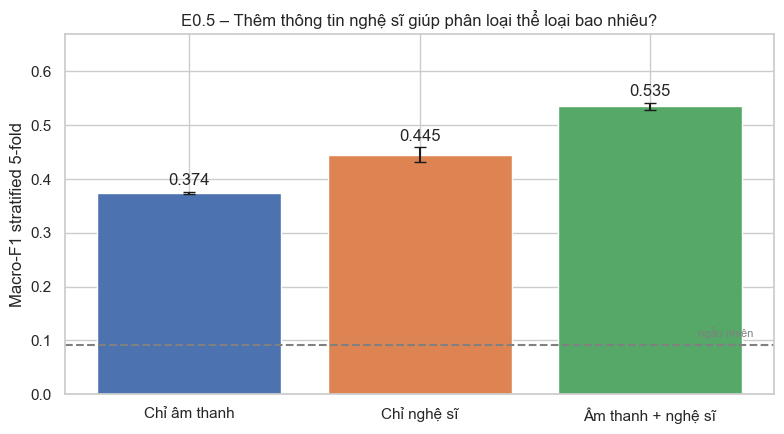

,macro_F1,macro_F1_std,accuracy,accuracy_std
cach,,,,
Chỉ âm thanh,0.374,0.002,0.371,0.004
Chỉ nghệ sĩ,0.445,0.014,0.451,0.010
Âm thanh + nghệ sĩ,0.535,0.007,0.542,0.005


In [19]:
from sklearn.metrics import f1_score, accuracy_score
artist = train["Artist Name"]
global_major = y.mode().iloc[0]
rows, seen_rates, seen_acc = [], [], []
for fold, (tr_idx, va_idx) in enumerate(skf.split(Xa, y)):
    model = logit().fit(Xa.iloc[tr_idx], y.iloc[tr_idx])
    p_audio = pd.Series(model.predict(Xa.iloc[va_idx]), index=va_idx)
    art_major = (pd.DataFrame({"a": artist.iloc[tr_idx], "c": y.iloc[tr_idx]})
                   .groupby("a")["c"].agg(lambda s: s.value_counts().idxmax()))
    a_va = artist.iloc[va_idx]
    seen = a_va.isin(art_major.index).to_numpy()
    p_artist = pd.Series(np.where(seen, a_va.map(art_major), global_major), index=va_idx)
    p_combo = pd.Series(np.where(seen, a_va.map(art_major), p_audio), index=va_idx)
    yt = y.iloc[va_idx]
    for name, p in [("Chỉ âm thanh", p_audio), ("Chỉ nghệ sĩ", p_artist), ("Âm thanh + nghệ sĩ", p_combo)]:
        rows.append({"cach": name, "fold": fold, "macro_F1": f1_score(yt, p.astype(int), average="macro"),
                     "accuracy": accuracy_score(yt, p.astype(int))})
    seen_rates.append(seen.mean())
    seen_acc.append(accuracy_score(yt[seen], p_artist[seen].astype(int)))

e05 = pd.DataFrame(rows)
e05_tbl = e05.groupby("cach", sort=False)[["macro_F1", "accuracy"]].agg(["mean", "std"]).round(3)
e05_tbl.columns = ["macro_F1", "macro_F1_std", "accuracy", "accuracy_std"]
e05_tbl.to_csv(FIG / "c2_E0.5_nghe_si.csv")
seen_rate, seen_artist_acc = float(np.mean(seen_rates)), float(np.mean(seen_acc))
test_seen = float(test["Artist Name"].isin(train["Artist Name"]).mean())
print(f"Trong mỗi fold, {seen_rate:.0%} bài có nghệ sĩ đã gặp ở phần huấn luyện "
      f"(ở tập test thật: {test_seen:.0%}); với các bài này, đoán theo nghệ sĩ đúng {seen_artist_acc:.0%}.")

fig, ax = plt.subplots(figsize=(8, 4.5))
order = ["Chỉ âm thanh", "Chỉ nghệ sĩ", "Âm thanh + nghệ sĩ"]
vals, errs = e05_tbl.loc[order, "macro_F1"], e05_tbl.loc[order, "macro_F1_std"]
bars = ax.bar(order, vals, yerr=errs, capsize=4, color=["#4C72B0", "#DD8452", "#55A868"])
for b, v, e in zip(bars, vals, errs):
    ax.text(b.get_x() + b.get_width() / 2, v + e + 0.012, f"{v:.3f}", ha="center")
ax.axhline(baseline_f1, ls="--", color="gray"); ax.text(2.45, baseline_f1 + 0.015, "ngẫu nhiên", fontsize=8, color="gray", ha="right")
ax.set_ylabel("Macro-F1 stratified 5-fold"); ax.set_ylim(0, max(vals) * 1.25)
ax.set_title("E0.5 – Thêm thông tin nghệ sĩ giúp phân loại thể loại bao nhiêu?")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.5_nghe_si.png", dpi=150); plt.show()
e05_tbl

## Tóm tắt E0.5

In [20]:
summary = f"""E0.5 (C2): macro-F1 chỉ âm thanh {e05_tbl.at['Chỉ âm thanh', 'macro_F1']:.3f}, chỉ nghệ sĩ {e05_tbl.at['Chỉ nghệ sĩ', 'macro_F1']:.3f}, âm thanh + nghệ sĩ {e05_tbl.at['Âm thanh + nghệ sĩ', 'macro_F1']:.3f}.
  {seen_rate:.0%} bài có nghệ sĩ đã gặp (test thật: {test_seen:.0%}); với các bài này đoán theo nghệ sĩ đúng {seen_artist_acc:.0%}."""
log.info("Tóm tắt E0.5:\n" + summary)
(FIG / "c2_E0.5_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:16:30 | INFO | Tóm tắt E0.5:
E0.5 (C2): macro-F1 chỉ âm thanh 0.374, chỉ nghệ sĩ 0.445, âm thanh + nghệ sĩ 0.535.
  59% bài có nghệ sĩ đã gặp (test thật: 64%); với các bài này đoán theo nghệ sĩ đúng 63%.


174

---
# Phần E0.6
> Nguồn: `notebooks/eda/01_E0.6_tach_lop_pca_tsne_Han.ipynb`

## E0.6 – Các thể loại có tách được nhau không?

Chiếu 14 đặc trưng (đã chuẩn hóa) xuống 2 chiều bằng **PCA** (giữ cấu trúc tuyến tính) và **t-SNE** (giữ lân cận cục bộ, chạy trên 4000 bài lấy mẫu phân tầng), tô màu theo thể loại. Đo thêm **silhouette** theo nhãn thể loại: gần 1 là các thể loại tách rời, gần 0 hoặc âm là chồng lấn.

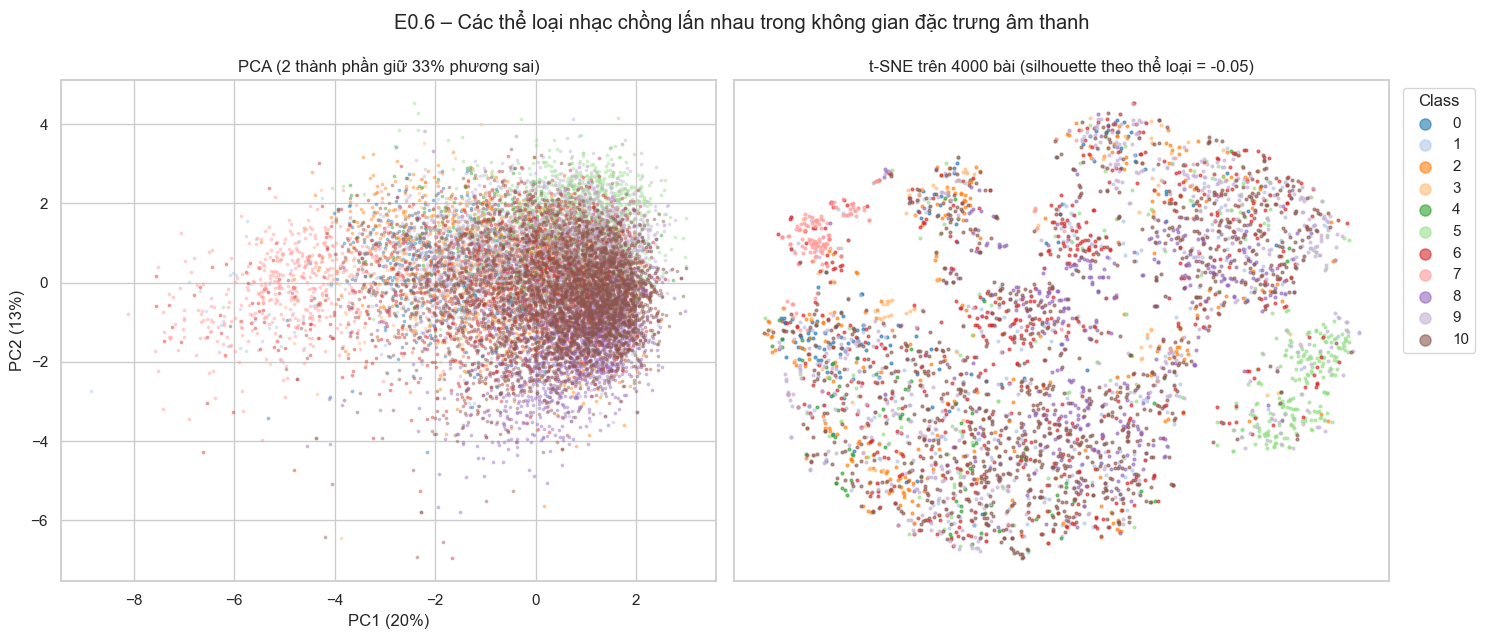

Silhouette toàn bộ: -0.049. PCA 2 chiều giữ 33% phương sai.


,so_bai,silhouette_1_vs_con_lai
7,461,0.276
5,1157,0.104
3,322,0.075
8,1483,0.034
2,1018,0.022
6,2069,0.001
0,500,-0.000
10,3959,-0.016
9,2019,-0.019
1,1098,-0.035


In [21]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split

Z = StandardScaler().fit_transform(Xa)
pca = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca.transform(Z)
idx_s, _ = train_test_split(np.arange(len(y)), train_size=4000, stratify=y, random_state=SEED)
T = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(Z[idx_s])
sil_all = silhouette_score(Z[idx_s], y.iloc[idx_s])
sil_per = pd.Series({k: silhouette_score(Z[idx_s], (y.iloc[idx_s] == k).astype(int)) for k in sorted(y.unique())})
pca_var = pca.explained_variance_ratio_

palette = sns.color_palette("tab20", n_colors=y.nunique())
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for k, col in zip(sorted(y.unique()), palette):
    m = (y == k).to_numpy()
    axes[0].scatter(P[m, 0], P[m, 1], s=3, alpha=0.35, color=col, label=str(k))
    ms = (y.iloc[idx_s] == k).to_numpy()
    axes[1].scatter(T[ms, 0], T[ms, 1], s=4, alpha=0.6, color=col, label=str(k))
axes[0].set_title(f"PCA (2 thành phần giữ {pca_var.sum():.0%} phương sai)")
axes[0].set_xlabel(f"PC1 ({pca_var[0]:.0%})"); axes[0].set_ylabel(f"PC2 ({pca_var[1]:.0%})")
axes[1].set_title(f"t-SNE trên 4000 bài (silhouette theo thể loại = {sil_all:.2f})")
axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].legend(title="Class", markerscale=4, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle("E0.6 – Các thể loại nhạc chồng lấn nhau trong không gian đặc trưng âm thanh")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.6_tach_lop.png", dpi=150); plt.show()

e06_tbl = pd.DataFrame({"so_bai": y.value_counts().sort_index(), "silhouette_1_vs_con_lai": sil_per.round(3)})
e06_tbl.to_csv(FIG / "c2_E0.6_silhouette.csv")
print(f"Silhouette toàn bộ: {sil_all:.3f}. PCA 2 chiều giữ {pca_var.sum():.0%} phương sai.")
e06_tbl.sort_values("silhouette_1_vs_con_lai", ascending=False)

## Tóm tắt E0.6

In [22]:
summary = f"""E0.6 (C2): silhouette theo thể loại = {sil_all:.2f} (gần 0 là chồng lấn); PCA 2 chiều giữ {pca_var.sum():.0%} phương sai.
  Thể loại tách rõ nhất: {', '.join(str(k) for k in sil_per.sort_values(ascending=False).index[:2])}; chồng lấn nhiều nhất: {', '.join(str(k) for k in sil_per.sort_values().index[:2])}."""
log.info("Tóm tắt E0.6:\n" + summary)
(FIG / "c2_E0.6_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:16:41 | INFO | Tóm tắt E0.6:
E0.6 (C2): silhouette theo thể loại = -0.05 (gần 0 là chồng lấn); PCA 2 chiều giữ 33% phương sai.
  Thể loại tách rõ nhất: 7, 5; chồng lấn nhiều nhất: 4, 1.


156

---
# Tóm tắt toàn bộ EDA

In [23]:
tom_tat = "\n".join((FIG / f"c2_{ma}_tom_tat.txt").read_text(encoding="utf-8")
                    for ma in ["E0.1", "E0.2", "E0.3", "E0.4", "E0.5", "E0.6"])
(FIG / "c2_E0_tong_hop_tom_tat.txt").write_text(tom_tat, encoding="utf-8")
log.info("Tóm tắt EDA tổng hợp:\n" + tom_tat)

2026-11-14 18:16:41 | INFO | Tóm tắt EDA tổng hợp:
E0.1 (C2): 14396 bài train, 3600 bài test, 11 thể loại, 14 đặc trưng số + 2 cột văn bản (Artist Name, Track Name).
  Mất cân bằng lớp: lớp 10 có 3959 bài, lớp 4 có 310 bài (gấp 12.8 lần).
  Thiếu: instrumentalness (25%), key (11%), Popularity (2%).
  duration_in min/ms lẫn 2 đơn vị (2075 bài ghi theo phút); key không có giá trị 0 nên ô trống nhiều khả năng là key = 0.
  63% bài của nghệ sĩ có ≥ 2 bài cùng thể loại với các bài khác của nghệ sĩ đó; 64% nghệ sĩ ở test đã có trong train.
E0.2 (C2): xếp hạng đặc trưng: acousticness, energy, danceability, speechiness, loudness, instrumentalness, Popularity, valence, duration_min, tempo.
  Đặc trưng đơn lẻ tốt nhất: energy (macro-F1 = 0.153, ngẫu nhiên ≈ 0.091).
E0.3 (C2): ngoại lai cực đoan nhiều nhất ở instrumentalness (18.1%), speechiness (7.1%), liveness (1.8%).
  Cặp tương quan > 0.7: energy–loudness (0.77); energy–acousticness (-0.75). VIF lớn nhất energy = 4.3.
E0.4 (C2): sweet spot 12

## Nhật ký

- 14/11/2026 – Gộp 6 notebook EDA con (E0.1 → E0.6) thành bản hoàn chỉnh `00_EDA_tong_hop_C2_Han.ipynb` bằng script `gop_eda.py`. Commit `eaa2795`.